## 6. 리뷰 글 분석: 왜 맞지 않았는가

**왜 하는가**
앞선 분석으로 AI가 pear 고객의 작은 옷을 덜 맞힌다는 것은 확인했지만, **그 이유**는 숫자만으로 알 수 없다.
데이터에는 고객이 직접 쓴 리뷰 글(예: "엉덩이가 너무 꼈어요")이 있으므로, 이를 분석해 체형별로 어느 부위 때문에 옷이 맞지 않았는지 확인한다.
특정 부위에 대한 불만이 pear에 몰려 있다면, AI가 그 부위의 치수 정보를 갖지 못해 pear를 틀린다고 설명할 수 있다.

**어떻게 하는가**
1. 실제 결과가 작음·큼인 리뷰를 체형별로 무작위 추출한다 (시드 42).
2. 언어 모델(Gemini, `gemini-3.8-flash`)에 리뷰를 하나씩 입력하고, 맞지 않은 부위를 정해진 목록에서 고르게 한다.
   - 부위 목록: 가슴, 허리, 엉덩이, 어깨, 팔, 기장, 전체, 언급 없음
   - 목록을 고정해 "힙", "골반"처럼 같은 뜻이 따로 집계되지 않게 한다.
   - 답은 정해진 형식(JSON)으로만 받고, 같은 리뷰에 같은 답이 나오도록 무작위성을 끈다 (temperature 0).
3. 일부 리뷰(50~100개)는 사람이 직접 읽고 부위를 표시한 뒤, 언어 모델 결과와의 일치율을 확인한다.
4. 체형별로 작음·큼 리뷰에서 각 부위가 언급된 비율을 계산한다.

**주의점**
- 언어 모델도 틀릴 수 있으므로, 사람 검수 일치율을 함께 보고한다.
- 리뷰를 쓴 고객의 표현에 따라 부위가 드러나지 않는 경우가 있다 ("언급 없음").
- 사용한 모델 이름, 실행 날짜, 프롬프트 전문을 기록해 재현할 수 있게 한다.

In [ ]:
# 내 키로 쓸 수 있는 모델 중 이름에 'flash'가 들어간 것만 보기
for m in client.models.list():
    if 'flash' in m.name:
        print(m.name)

models/gemini-2.5-flash
models/gemini-2.5-flash-preview-tts
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-tts
models/gemini-2.5-flash-native-audio-latest
models/gemini-2.5-flash-native-audio-preview-09-2025
models/gemini-2.5-flash-native-audio-preview-12-2025
models/gemini-3.1-flash-live-preview


In [ ]:
import time
from google.genai import errors

def ask(prompt, model='gemini-3.8-flash', tries=5):
    # 서버가 바쁘면(503) 기다렸다가 다시 시도. 기다리는 시간은 2, 4, 8, 16초로 늘림
    for i in range(tries):
        try:
            return client.models.generate_content(model=model, contents=prompt).text
        except errors.ServerError as e:
            wait = 2 ** (i + 1)
            print(f"서버 바쁨, {wait}초 뒤 다시 시도 ({i+1}/{tries})")
            time.sleep(wait)
    raise RuntimeError("여러 번 시도했지만 실패. 잠시 뒤 다시 실행하세요.")

print(ask('안녕이라고만 답해줘'))

서버 바쁨, 2초 뒤 다시 시도 (1/5)
서버 바쁨, 4초 뒤 다시 시도 (2/5)
서버 바쁨, 8초 뒤 다시 시도 (3/5)
서버 바쁨, 16초 뒤 다시 시도 (4/5)
서버 바쁨, 32초 뒤 다시 시도 (5/5)


RuntimeError: 여러 번 시도했지만 실패. 잠시 뒤 다시 실행하세요.

In [ ]:
print(ask('안녕이라고만 답해줘', model='gemini-3.5-flash'))

안녕


In [ ]:
# ── 6-1. 분석할 리뷰 뽑기 ──
import pandas as pd, numpy as np, json, os
from google.colab import drive
drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/3-2/시각화 학술제"
RES_DIR = f"{BASE}/결과표/v2"
data = pd.read_csv(f"{BASE}/데이터/정리/정리데이터.csv", keep_default_na=False, na_values=[''])

# 작음·큼 리뷰 중 내용이 있는 것만 (N/A 같은 빈 리뷰 제외)
bad = data[data['label'].isin([0, 2])].copy()
bad = bad[bad['review_text'].fillna('').str.len() > 20]

# 체형 × 결과(작음·큼)마다 25개씩 무작위 추출 → 7체형 × 2 × 25 = 350개
sample = (bad.groupby(['body_type', 'label'], group_keys=False)
             .apply(lambda d: d.sample(min(25, len(d)), random_state=42)))
sample = sample[['review_id', 'body_type', 'fit', 'label', 'review_text']].reset_index(drop=True)
sample.to_csv(f"{BASE}/데이터/정리/리뷰샘플.csv", index=False)
print(len(sample))
print(sample.groupby(['body_type', 'fit']).size().unstack())

Mounted at /content/drive
350
fit                large  small
body_type                      
apple                 25     25
athletic              25     25
full bust             25     25
hourglass             25     25
pear                  25     25
petite                25     25
straight & narrow     25     25


/tmp/ipykernel_1761/76350910.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: d.sample(min(25, len(d)), random_state=42)))


In [ ]:
import time
from google.genai import errors, types

def ask(prompt, model='gemini-3.5-flash', tries=5):
    # temperature=0: 같은 리뷰에는 항상 같은 답이 나오게 무작위성을 끔
    # seed=42: 무작위성이 남아 있는 부분도 고정
    config = types.GenerateContentConfig(temperature=0, seed=42)
    for i in range(tries):
        try:
            return client.models.generate_content(model=model, contents=prompt, config=config).text
        except errors.ServerError:
            wait = 2 ** (i + 1)
            print(f"서버 바쁨, {wait}초 뒤 다시 시도 ({i+1}/{tries})")
            time.sleep(wait)
    raise RuntimeError("여러 번 시도했지만 실패. 잠시 뒤 다시 실행하세요.")

In [ ]:
# ── 6-2. Gemini로 부위 뽑기 (10개 테스트) ──
MODEL = 'gemini-3.5-flash'
PARTS = ['bust', 'waist', 'hip', 'shoulder', 'arm', 'length', 'overall', 'none']

def make_prompt(text, fit):
    # Gemini에게 보낼 질문: 정해진 부위 목록 중에서만 고르고, JSON으로만 답하게 함
    return f"""You are labeling clothing fit reviews.
The customer said the item was too {fit}.
Read the review and choose which body parts the fit problem was about.
Choose only from this list: {PARTS}
- 'overall' = the whole item was small/large without a specific part
- 'none' = the review does not mention why
Answer ONLY in JSON like {{"parts": ["hip", "waist"]}}.

Review: \"\"\"{text}\"\"\""""

def parse(ans):
    # 답에서 JSON 부분만 꺼내고, 목록에 없는 단어는 버림
    try:
        s = ans[ans.find('{'): ans.rfind('}') + 1]
        parts = [p for p in json.loads(s).get('parts', []) if p in PARTS]
        return parts if parts else ['none']
    except Exception:
        return ['parse_error']

# 먼저 10개만 테스트: 결과 | 뽑힌 부위 | 리뷰 앞부분
for _, r in sample.head(10).iterrows():
    ans = ask(make_prompt(r['review_text'], r['fit']), model=MODEL)
    print(r['fit'], '|', parse(ans), '|', r['review_text'][:100])

small | ['bust'] | This dress has no stretch and ran small. I normally wear and M or and 8 and it was way to tight on t
small | ['bust'] | I rented this dress for vacation. It's so feminine, classy, and unique, absolutely loved wearing it.
small | ['bust'] | It is a little on the small end so if you are between sizes go up not down. But it is an A-line fit 
small | ['overall'] | Loved the length, but it ran very small.  Way too clingy.
서버 바쁨, 2초 뒤 다시 시도 (1/5)
small | ['waist'] | This dress definitely runs a little small around the midsection. The top lace cover was a little loo
small | ['waist'] | I liked this dress a lot. I don't think it looked good on me though. My body is too straight to make
small | ['bust', 'waist'] | Dress was amazing - just slightly tight across the bust/waist, but not too bad - I wore it anyway! G
small | ['overall'] | The dress was super flattering and gorgeous. The material is heavy enough that it looks and feels ex
small | ['waist', 'hip'] | I have curves a

In [ ]:
# ── 6-3. 리뷰 부위 추출 (런타임이 끊겨도 이 셀만 다시 돌리면 이어서 함) ──
!pip install -q google-genai

import os, json, time
import pandas as pd
from google.colab import drive, userdata
from google import genai
from google.genai import errors, types

# [1] 드라이브 연결 (이미 연결돼 있으면 그냥 넘어감)
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/3-2/시각화 학술제"
SAMPLE = f"{BASE}/데이터/정리/리뷰샘플.csv"        # 6-1에서 저장한 350개 (다시 뽑지 않음)
OUT    = f"{BASE}/데이터/정리/부위추출결과.csv"     # 결과가 쌓이는 파일

# [2] Gemini 연결
client = genai.Client(api_key=userdata.get('GEMINI_API_KEY'))
MODEL = 'gemini-3.5-flash'
CONFIG = types.GenerateContentConfig(temperature=0, seed=42)   # 무작위성 고정
PARTS = ['bust', 'waist', 'hip', 'shoulder', 'arm', 'length', 'overall', 'none']

def make_prompt(text, fit):
    return f"""You are labeling clothing fit reviews.
The customer said the item was too {fit}.
Read the review and choose which body parts the fit problem was about.
Choose only from this list: {PARTS}
- 'overall' = the whole item was small/large without a specific part
- 'none' = the review does not mention why
Answer ONLY in JSON like {{"parts": ["hip", "waist"]}}.

Review: \"\"\"{text}\"\"\""""

def parse(ans):
    # 답에서 JSON만 꺼내고, 목록에 없는 단어는 버림
    try:
        s = ans[ans.find('{'): ans.rfind('}') + 1]
        parts = [p for p in json.loads(s).get('parts', []) if p in PARTS]
        return parts if parts else ['none']
    except Exception:
        return ['parse_error']

def ask(prompt):
    # 서버 바쁨(503)이면 점점 길게 기다리며 재시도, 무료 한도(429)면 1분 쉬고 재시도
    wait = 2
    while True:
        try:
            return client.models.generate_content(model=MODEL, contents=prompt, config=CONFIG).text
        except errors.ServerError:
            print(f"서버 바쁨, {wait}초 대기"); time.sleep(wait); wait = min(wait * 2, 120)
        except errors.ClientError as e:
            if '429' in str(e):
                print("무료 한도에 걸림, 60초 대기"); time.sleep(60)
            else:
                raise

# [3] 샘플과 지금까지 결과 불러오기
sample = pd.read_csv(SAMPLE, keep_default_na=False, na_values=[''])
if os.path.exists(OUT):
    done = pd.read_csv(OUT)
    rows = done.to_dict('records')
    done_ids = set(done['review_id'])
else:
    rows, done_ids = [], set()

todo = sample[~sample['review_id'].isin(done_ids)]
print(f"전체 {len(sample)}개 중 완료 {len(done_ids)}개, 남은 {len(todo)}개")

# [4] 남은 리뷰만 처리, 10개마다 저장
for n, (_, r) in enumerate(todo.iterrows(), 1):
    ans = ask(make_prompt(r['review_text'], r['fit']))
    rows.append({'review_id': r['review_id'], 'raw': ans, 'parts': '|'.join(parse(ans))})
    time.sleep(4)   # 분당 요청 수 제한을 넘지 않게 천천히

    if n % 10 == 0 or n == len(todo):
        pd.DataFrame(rows).to_csv(OUT, index=False)
        print(f"{len(rows)}/{len(sample)} 저장")

print("완료" if len(rows) == len(sample) else "아직 남음, 이 셀을 다시 실행하세요")

Mounted at /content/drive
전체 350개 중 완료 0개, 남은 350개
서버 바쁨, 2초 대기
무료 한도에 걸림, 60초 대기
서버 바쁨, 2초 대기
무료 한도에 걸림, 60초 대기
무료 한도에 걸림, 60초 대기
무료 한도에 걸림, 60초 대기
무료 한도에 걸림, 60초 대기
무료 한도에 걸림, 60초 대기
무료 한도에 걸림, 60초 대기


KeyboardInterrupt: 

In [ ]:
# 429 오류 내용을 그대로 보기 (분당 한도인지, 하루 한도인지 나옴)
try:
    client.models.generate_content(model=MODEL, contents='hi', config=CONFIG)
    print("지금은 정상")
except Exception as e:
    print(e)

429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.6-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.\nPlease retry in 5h7m21.833240675s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'description': 'Generate content requests per day limit exceeded on Free Tier. See https://ai.google

In [ ]:
# 요청한 모델 이름 vs 실제로 답한 모델 이름 비교 (모델마다 요청 1번씩 씀)
for name in ['gemini-3.5-flash-lite', 'gemini-3.8-flash']:
    try:
        r = client.models.generate_content(model=name, contents='hi')
        print(f"요청: {name}  →  실제 응답: {r.model_version}")
    except Exception as e:
        print(f"요청: {name}  →  오류: {str(e)[:80]}")

요청: gemini-3.5-flash-lite  →  실제 응답: gemini-3.5-flash-lite
요청: gemini-3.8-flash  →  오류: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently exp


In [ ]:
# ── 6-3. 리뷰 부위 추출 (25개씩 묶어서 전송, 끊겨도 이어서 함) ──
!pip install -q google-genai

import os, json, time
import pandas as pd
from google.colab import drive, userdata
from google import genai
from google.genai import errors, types

# [1] 드라이브 연결 (이미 연결돼 있으면 넘어감)
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

BASE   = "/content/drive/MyDrive/3-2/시각화 학술제"
SAMPLE = f"{BASE}/데이터/정리/리뷰샘플.csv"        # 6-1에서 저장한 350개 (다시 뽑지 않음)
OUT    = f"{BASE}/데이터/정리/부위추출결과.csv"     # 결과가 쌓이는 파일

# [2] Gemini 설정
client = genai.Client(api_key=userdata.get('GEMINI_API_KEY'))
MODEL  = 'gemini-3.5-flash-lite'                                # 요청 이름 = 실제 응답 모델 확인됨
CONFIG = types.GenerateContentConfig(temperature=0, seed=42)    # 무작위성 고정
PARTS  = ['bust', 'waist', 'hip', 'shoulder', 'arm', 'length', 'overall', 'none']
BATCH  = 25   # 한 번에 보낼 리뷰 수 → 350개를 14번에 처리 (하루 한도 20번 안)

def make_prompt(batch):
    # 리뷰 여러 개를 번호와 함께 보내고, 번호별로 부위를 JSON으로 받음
    items = "\n".join(f'{{"id": {r.review_id}, "fit": "too {r.fit}", "review": {json.dumps(r.review_text)}}}'
                      for r in batch.itertuples())
    return f"""You are labeling clothing fit reviews.
For each review, the customer said the item was too small or too large (given in "fit").
Choose which body parts the fit problem was about, ONLY from this list: {PARTS}
- 'overall' = the whole item was small/large without a specific part
- 'none' = the review does not mention why
Return ONLY JSON in this exact form, one entry per review, same ids:
{{"results": [{{"id": 123, "parts": ["hip", "waist"]}}, ...]}}

Reviews:
{items}"""

def parse(ans):
    # 답에서 JSON을 꺼내 {리뷰번호: 부위 목록}으로 바꿈. 목록에 없는 단어는 버림
    s = ans[ans.find('{'): ans.rfind('}') + 1]
    out = {}
    for x in json.loads(s).get('results', []):
        parts = [p for p in x.get('parts', []) if p in PARTS]
        out[int(x['id'])] = parts if parts else ['none']
    return out

def ask(prompt):
    # 서버 바쁨(503): 점점 길게 기다리며 재시도 / 하루 한도: 멈춤 / 분당 한도: 1분 쉬고 재시도
    wait = 2
    while True:
        try:
            return client.models.generate_content(model=MODEL, contents=prompt, config=CONFIG)
        except errors.ServerError:
            print(f"서버 바쁨, {wait}초 대기"); time.sleep(wait); wait = min(wait * 2, 120)
        except errors.ClientError as e:
            if 'PerDay' in str(e):
                raise RuntimeError("오늘 무료 한도를 다 씀. 내일 이 셀을 다시 실행하면 이어서 함.")
            if '429' in str(e):
                print("분당 한도, 60초 대기"); time.sleep(60)
            else:
                raise

# [3] 샘플과 지금까지 결과 불러오기
sample = pd.read_csv(SAMPLE, keep_default_na=False, na_values=[''])
rows = pd.read_csv(OUT).to_dict('records') if os.path.exists(OUT) else []
done_ids = {r['review_id'] for r in rows}
todo = sample[~sample['review_id'].isin(done_ids)]
print(f"전체 {len(sample)}개 중 완료 {len(done_ids)}개, 남은 {len(todo)}개")

# [4] 25개씩 묶어서 처리, 묶음마다 저장
for start in range(0, len(todo), BATCH):
    batch = todo.iloc[start:start + BATCH]
    resp = ask(make_prompt(batch))
    try:
        got = parse(resp.text)
    except Exception:
        print("답 형식이 깨짐, 이 묶음은 건너뜀 (다시 실행하면 재시도)"); continue
    for rid in batch['review_id']:
        if rid in got:   # 답에 빠진 리뷰는 저장 안 함 → 다음 실행 때 다시 보냄
            rows.append({'review_id': rid, 'parts': '|'.join(got[rid]),
                         'model_version': resp.model_version})
    pd.DataFrame(rows).to_csv(OUT, index=False)
    print(f"{len(rows)}/{len(sample)} 저장 (응답 모델: {resp.model_version})")
    time.sleep(5)

print("완료" if len(rows) == len(sample) else "아직 남음, 이 셀을 다시 실행하세요")

전체 350개 중 완료 0개, 남은 350개
서버 바쁨, 2초 대기
25/350 저장 (응답 모델: gemini-3.5-flash-lite)
50/350 저장 (응답 모델: gemini-3.5-flash-lite)
75/350 저장 (응답 모델: gemini-3.5-flash-lite)
100/350 저장 (응답 모델: gemini-3.5-flash-lite)
서버 바쁨, 2초 대기
125/350 저장 (응답 모델: gemini-3.5-flash-lite)
서버 바쁨, 2초 대기
150/350 저장 (응답 모델: gemini-3.5-flash-lite)
175/350 저장 (응답 모델: gemini-3.5-flash-lite)
서버 바쁨, 2초 대기
서버 바쁨, 4초 대기
서버 바쁨, 8초 대기
200/350 저장 (응답 모델: gemini-3.5-flash-lite)
서버 바쁨, 2초 대기
225/350 저장 (응답 모델: gemini-3.5-flash-lite)
250/350 저장 (응답 모델: gemini-3.5-flash-lite)
275/350 저장 (응답 모델: gemini-3.5-flash-lite)
300/350 저장 (응답 모델: gemini-3.5-flash-lite)
325/350 저장 (응답 모델: gemini-3.5-flash-lite)
350/350 저장 (응답 모델: gemini-3.5-flash-lite)
완료


In [ ]:
# ── 6-4. 체형별 부위 집계 (저장된 파일만 사용) ──
import numpy as np
import matplotlib.pyplot as plt

RES_DIR = f"{BASE}/결과표/v2"
FIG_DIR = f"{BASE}/그래프/v2"
order = ['hourglass', 'athletic', 'pear', 'petite', 'full bust', 'straight & narrow', 'apple']
PART_KO = {'bust': '가슴', 'waist': '허리', 'hip': '엉덩이', 'shoulder': '어깨',
           'arm': '팔', 'length': '기장', 'overall': '전체', 'none': '언급 없음'}

# 리뷰 정보와 부위 결과를 합침
res = pd.read_csv(OUT).merge(sample[['review_id', 'body_type', 'fit']], on='review_id')
print("리뷰 수:", len(res), "/ 사용 모델:", res['model_version'].unique())

# 리뷰마다 부위가 여러 개일 수 있어서, 부위별로 '언급했는지(1/0)' 열을 만듦
for p in PART_KO:
    res[p] = res['parts'].str.split('|').apply(lambda x: int(p in x))

# 체형 × 결과(작음·큼)별로 각 부위를 언급한 리뷰 비율
part_tbl = (res.groupby(['fit', 'body_type'])[list(PART_KO)].mean()
               .rename(columns=PART_KO).round(3))
display(part_tbl)
part_tbl.to_csv(f"{RES_DIR}/8_리뷰_부위분석.csv", encoding='utf-8-sig')

리뷰 수: 350 / 사용 모델: ['gemini-3.5-flash-lite']


가슴    허리   엉덩이    어깨     팔    기장    전체  언급 없음
fit   body_type                                                         
large apple              0.20  0.08  0.04  0.04  0.00  0.12  0.80   0.00
      athletic           0.08  0.04  0.04  0.00  0.12  0.04  0.76   0.12
      full bust          0.28  0.12  0.00  0.04  0.04  0.04  0.28   0.28
      hourglass          0.24  0.08  0.00  0.00  0.04  0.28  0.68   0.04
      pear               0.08  0.08  0.04  0.04  0.08  0.16  0.68   0.04
      petite             0.16  0.12  0.04  0.08  0.04  0.08  0.44   0.20
      straight & narrow  0.36  0.12  0.00  0.04  0.04  0.16  0.28   0.24
small apple              0.32  0.20  0.08  0.04  0.00  0.12  0.52   0.00
      athletic           0.20  0.12  0.12  0.04  0.00  0.16  0.40   0.16
      full bust          0.60  0.12  0.04  0.00  0.08  0.04  0.24   0.04
      hourglass          0.24  0.08  0.20  0.04  0.12  0.08  0.24   0.12
      pear               0.20  0.08  0.24  0.04  0.00  0.24  0.44   0.08
      petite             0.12  0.20  0.04  0.00  0.08  0.04  0.48   0.08
      straight & narrow  0.12  0.24  0.24  0.00  0.08  0.16  0.52   0.00

In [ ]:
!pip install -q koreanize-matplotlib
import koreanize_matplotlib

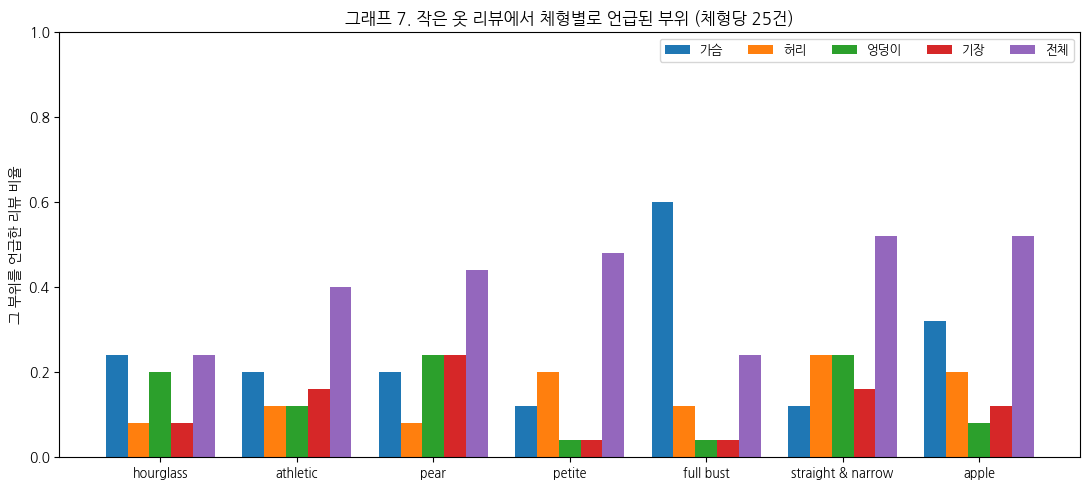

In [ ]:
# ── 그래프 7: 작은 옷 리뷰에서 체형별로 많이 언급된 부위 ──
show = ['가슴', '허리', '엉덩이', '기장', '전체']
small_tbl = part_tbl.loc['small'].loc[order, show]

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(order)); w = 0.16
for i, p in enumerate(show):
    ax.bar(x + (i - 2) * w, small_tbl[p], w, label=p)
ax.set_xticks(x); ax.set_xticklabels(order, fontsize=9)
ax.set_ylabel('그 부위를 언급한 리뷰 비율'); ax.set_ylim(0, 1); ax.legend(ncol=5, fontsize=9)
ax.set_title('그래프 7. 작은 옷 리뷰에서 체형별로 언급된 부위 (체형당 25건)')
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/7_리뷰_작은옷_부위.png", dpi=300); plt.show()

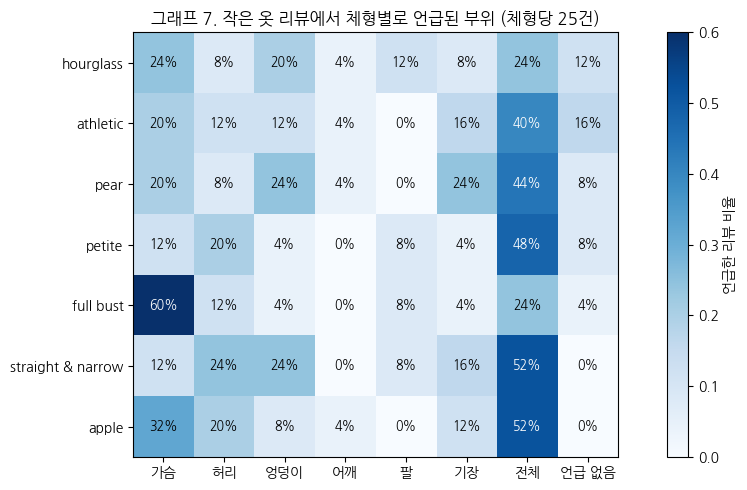

In [ ]:
# ── 그래프 7 (히트맵 버전): 작은 옷 리뷰에서 체형별 언급 부위 ──
show = ['가슴', '허리', '엉덩이', '어깨', '팔', '기장', '전체', '언급 없음']
hm = part_tbl.loc['small'].loc[order, show]

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(hm.values, cmap='Blues', vmin=0, vmax=0.6)
ax.set_xticks(range(len(show))); ax.set_xticklabels(show)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)

# 칸마다 비율(%) 숫자 표시, 진한 칸은 흰 글씨
for i in range(len(order)):
    for j in range(len(show)):
        v = hm.values[i, j]
        ax.text(j, i, f"{v*100:.0f}%", ha='center', va='center',
                color='white' if v > 0.35 else 'black', fontsize=9)

fig.colorbar(im, ax=ax, label='언급한 리뷰 비율')
ax.set_title('그래프 7. 작은 옷 리뷰에서 체형별로 언급된 부위 (체형당 25건)')
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/7_리뷰_작은옷_부위.png", dpi=300); plt.show()

## 6-2. 리뷰 분석 결과: 왜 맞지 않았는가

**방법 요약**
작은 옷·큰 옷 리뷰를 체형마다 25건씩(총 350건) 뽑아, Gemini(`gemini-3.5-flash-lite`)로 맞지 않은 부위를 분류했다.
체형당 25건이므로 **4%p가 리뷰 1건**이다. 작은 차이는 우연일 수 있다.

**작은 옷 리뷰 결과**

| 체형 | 가장 많이 언급된 부위 |
| --- | --- |
| full bust | **가슴 60%** (25건 중 15건) |
| pear | 전체 44% · **엉덩이 24% · 기장 24%** |
| straight & narrow | 전체 52% · 허리 24% · 엉덩이 24% |
| hourglass | 가슴 24% · 전체 24% · 엉덩이 20% |
| 그 외 | 대부분 "전체적으로 작다" |

**큰 옷 리뷰 결과**
- 대부분 "전체적으로 크다"는 리뷰였다.
- hourglass는 기장 28%로, 큰 옷에서 기장이 길다는 불만이 상대적으로 많았다.

**해석**
- **full bust는 가슴 때문에 작다는 불만이 뚜렷하다.**
- pear는 엉덩이·기장 불만이 다른 체형보다 조금 많은 **경향**이 있으나, 차이가 리뷰 1~2건 수준이라 단정하기 어렵다.
- 데이터에는 가슴 사이즈는 있지만 엉덩이 치수는 없다. AI가 엉덩이 치수를 반영하지 못해 pear를 덜 맞혔을 **가능성**이 있다.

> 리뷰 분석은 앞선 결과의 **원인에 대한 힌트**를 제공한다. 확정적 결론이 아닌 가능한 설명으로 제시한다.

## 7. 인터랙티브 시연 화면 준비

**목적**
앞의 분석으로 "체형에 따라 AI 추천의 신뢰도가 다르고, 체형×결과별 기준으로 이를 맞출 수 있다"는 것을 확인했다.
이 결과를 직접 체험할 수 있도록, 키·몸무게·체형을 입력하면 **공통 기준과 체형×결과별 기준의 추천 결과를 나란히 보여주는 웹 화면**을 만든다.
같은 몸 크기에서 체형만 바꿨을 때 후보 묶음이 어떻게 달라지는지 확인할 수 있다.

**이 단계에서 하는 일**
지금까지는 시험용 데이터에 대한 AI의 답(예측 확률)만 저장했다.
웹 화면에서는 새로운 입력값에 바로 답해야 하므로, **AI 모델 자체와 보정·기준값**을 파일로 저장한다.

| 저장 파일 | 역할 |
| --- | --- |
| `model_v2.pkl` | 작음·맞음·큼 확률을 계산하는 모델 |
| `item_stats.csv` | 옷마다 작게·크게 나오는 정도 |
| `params.json` | 확률 보정값(T), conformal 기준값 |
| 결과표 `*.csv` | 연구 결과 대시보드용 |

> 저장된 파일만으로 v2 모델을 다시 학습한다. 나무 수가 64로 나오면 논문 결과와 동일한 모델이다.

In [14]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
# ── 웹 시연용 파일 만들기 (저장된 파일만으로 model2 다시 학습) ──
import os, json, shutil, joblib
import numpy as np, pandas as pd, lightgbm as lgb
from sklearn.utils.class_weight import compute_sample_weight

BASE = "/content/drive/MyDrive/3-2/시각화 학술제"
APP_DIR = f"{BASE}/웹시연"
os.makedirs(APP_DIR, exist_ok=True)

# [1] 데이터와 분할 불러오기 (23~25번 셀과 동일)
data = pd.read_csv(f"{BASE}/데이터/정리/정리데이터.csv", keep_default_na=False, na_values=[''])
data = data.merge(pd.read_csv(f"{BASE}/데이터/정리/분할명단.csv"), on='user_id')
for c in ['body_type', 'category']:
    data[c] = data[c].astype('category')
train = data[data['set'] == 'train']
features = ['height_cm', 'weight_kg', 'bust_band', 'cup_num', 'body_type', 'category', 'size', 'age']

# [2] 옷 정보 계산 (22번 셀과 동일, 저장된 덩어리 배정 사용)
m = 20
prior_s, prior_l = (train['label'] == 0).mean(), (train['label'] == 2).mean()

def item_stats(src):
    gi = src.groupby('item_id').agg(n=('label', 'size'), s=('label', lambda x: (x == 0).sum()),
                                     l=('label', lambda x: (x == 2).sum()), size_mean=('size', 'mean'))
    gi['item_small'] = (gi['s'] + m * prior_s) / (gi['n'] + m)
    gi['item_large'] = (gi['l'] + m * prior_l) / (gi['n'] + m)
    gi['item_n'] = gi['n']
    return gi[['item_small', 'item_large', 'size_mean', 'item_n']]

def add_item_feats(df, stats):
    out = df.join(stats, on='item_id')
    out['item_small'] = out['item_small'].fillna(prior_s)
    out['item_large'] = out['item_large'].fillna(prior_l)
    out['item_n'] = out['item_n'].fillna(0)
    out['size_diff'] = out['size'] - out['size_mean']
    return out.drop(columns='size_mean')

fold = pd.read_csv(f"{BASE}/데이터/정리/학습용_fold배정.csv").set_index('user_id')['fold']
fid = train['user_id'].map(fold).values
train2 = pd.concat([add_item_feats(train[fid == f], item_stats(train[fid != f])) for f in range(5)]).loc[train.index]
stats_all = item_stats(train)
features2 = features + ['item_small', 'item_large', 'item_n', 'size_diff']

# [3] model2 다시 학습 (23번 셀과 동일 설정)
rng = np.random.default_rng(42)
tr_users = train['user_id'].unique()
val_users = rng.choice(tr_users, size=int(len(tr_users) * 0.1), replace=False)
tr2, val2 = train2[~train2['user_id'].isin(val_users)], train2[train2['user_id'].isin(val_users)]

model2 = lgb.LGBMClassifier(objective='multiclass', n_estimators=3000, learning_rate=0.1,
                            num_leaves=31, class_weight='balanced', random_state=42, verbose=-1)
model2.fit(tr2[features2], tr2['label'], eval_set=[(val2[features2], val2['label'])],
           eval_sample_weight=[compute_sample_weight('balanced', val2['label'])],
           callbacks=[lgb.early_stopping(50, verbose=False)])
print("나무 수:", model2.best_iteration_, "(예전 결과 64와 같으면 똑같은 모델)")

# [4] 웹 시연에 필요한 파일 저장
joblib.dump(model2, f"{APP_DIR}/model_v2.pkl")
stats_all.reset_index().to_csv(f"{APP_DIR}/item_stats.csv", index=False)

saved = json.load(open(f"{BASE}/결과표/v2/설정값.json", encoding='utf-8'))   # 이미 저장된 T·기준값
params = {
    'features': features2,
    'categories': {'body_type': list(train['body_type'].cat.categories),
                   'category': list(train['category'].cat.categories)},
    'prior_small': float(prior_s), 'prior_large': float(prior_l),
    'T': saved['temperature_T'],
    'log_prior': [float(np.log(saved['학습용_정답비율'][k])) for k in ['작음', '맞음', '큼']],
    't_all': saved['공통_기준값'],
    't_bk': saved['체형결과별_기준값'],
}
json.dump(params, open(f"{APP_DIR}/params.json", 'w', encoding='utf-8'), ensure_ascii=False, indent=2)

for f in os.listdir(f"{BASE}/결과표/v2"):
    if f.endswith('.csv'):
        shutil.copy(f"{BASE}/결과표/v2/{f}", APP_DIR)
print(sorted(os.listdir(APP_DIR)))

나무 수: 64 (예전 결과 64와 같으면 똑같은 모델)
['1_체형별_재현율.csv', '2_키몸무게_통제.csv', '3_ECE_보정전후.csv', '4_예상vs실제.csv', '5_AUC.csv', '6_conformal_포함률_후보수.csv', '7_후보개수_분포.csv', '8_리뷰_부위분석.csv', 'item_stats.csv', 'model_v2.pkl', 'params.json']


In [16]:
os.chdir("/content/drive/MyDrive/3-2/시각화 학술제/웹시연")

In [17]:
import lightgbm, sklearn, pandas, numpy
reqs = f"""streamlit
plotly
joblib
pandas=={pandas.__version__}
numpy=={numpy.__version__}
scikit-learn=={sklearn.__version__}
lightgbm=={lightgbm.__version__}
"""
open("requirements.txt", "w").write(reqs)
print(reqs)

streamlit
plotly
joblib
pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
lightgbm==4.6.0



In [18]:
%%writefile app.py
# app.py — 체형별 공정성을 고려한 사이즈 추천 시연
import json, joblib
import numpy as np, pandas as pd
import streamlit as st
import plotly.graph_objects as go

st.set_page_config(page_title="체형별 사이즈 추천 시연", layout="wide")

@st.cache_resource
def load():
    model = joblib.load("model_v2.pkl")
    params = json.load(open("params.json", encoding="utf-8"))
    items = pd.read_csv("item_stats.csv")
    return model, params, items

model, P, items = load()
ORDER = ['hourglass', 'athletic', 'pear', 'petite', 'full bust', 'straight & narrow', 'apple']
KO = ['작음', '맞음', '큼']
CUP = {'aa': 0, 'a': 1, 'b': 2, 'c': 3, 'd': 4, 'd+': 4.5, 'dd': 5, 'ddd/e': 6, 'f': 7, 'g': 8, 'h': 9, 'i': 10, 'j': 11}

# 옷 성향 3단계: 리뷰 50개 이상인 옷들의 실제 분포에서 대표값을 뽑음
pop = items[items['item_n'] >= 50]
ITEM_TYPE = {
    '작게 나오는 옷': dict(item_small=pop['item_small'].quantile(0.9), item_large=pop['item_large'].quantile(0.1)),
    '보통':          dict(item_small=pop['item_small'].median(),     item_large=pop['item_large'].median()),
    '크게 나오는 옷': dict(item_small=pop['item_small'].quantile(0.1), item_large=pop['item_large'].quantile(0.9)),
}
ITEM_N = float(pop['item_n'].median())

def softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True)); return e / e.sum(axis=1, keepdims=True)

def predict(df):
    # 모델 원점수 → 원래 비율 되돌리기 → temperature scaling → 보정 확률
    X = df[P['features']].copy()
    for c in ['body_type', 'category']:
        X[c] = pd.Categorical(X[c], categories=P['categories'][c])
    z = model.predict(X, raw_score=True)
    return softmax((z + np.array(P['log_prior'])) / P['T'])

def candidate_sets(q, bt):
    common = [KO[k] for k in range(3) if 1 - q[k] <= P['t_all']]
    fair = [KO[k] for k in range(3) if 1 - q[k] <= P['t_bk'][f"{bt}_{KO[k]}"]]
    return common, fair

tab1, tab2 = st.tabs(["사이즈 추천 체험", "연구 결과 대시보드"])

# ── 탭 1: 사이즈 추천 체험 ──
with tab1:
    st.header("내 체형으로 사이즈 추천 받아보기")
    st.caption("두 기준 모두 '정답이 후보 안에 90% 들어간다'를 목표로 한다.")

    c1, c2, c3 = st.columns(3)
    with c1:
        height = st.slider("키 (cm)", 145, 190, 165)
        weight = st.slider("몸무게 (kg)", 40, 110, 60)
        age = st.slider("나이", 18, 70, 30)
    with c2:
        body = st.selectbox("체형", ORDER, index=ORDER.index('pear'))
        band = st.selectbox("가슴 둘레", [30, 32, 34, 36, 38, 40], index=2)
        cup = st.selectbox("컵", list(CUP), index=list(CUP).index('c'))
    with c3:
        category = st.selectbox("옷 종류", [c for c in P['categories']['category'] if c != 'other'])
        size = st.slider("주문 사이즈", 0, 30, 8)
        item_type = st.radio("이 옷은?", list(ITEM_TYPE), index=1, horizontal=True)
        size_diff = st.slider("다른 사람들이 빌린 평균 사이즈보다", -8, 8, 0,
                              help="0이면 이 옷을 빌린 사람들의 평균 사이즈로 주문한 것")

    def row(bt):
        return dict(height_cm=height, weight_kg=weight, bust_band=band, cup_num=CUP[cup],
                    body_type=bt, category=category, size=size, age=age,
                    item_n=ITEM_N, size_diff=size_diff, **ITEM_TYPE[item_type])

    q = predict(pd.DataFrame([row(body)]))[0]
    common, fair = candidate_sets(q, body)

    left, right = st.columns(2)
    with left:
        st.subheader("AI가 예상한 확률")
        fig = go.Figure(go.Bar(x=KO, y=q, text=[f"{v*100:.0f}%" for v in q], textposition='outside'))
        fig.update_layout(yaxis=dict(range=[0, 1], title='확률'), height=320, margin=dict(t=10))
        st.plotly_chart(fig, use_container_width=True)
    with right:
        st.subheader("추천 후보")
        st.metric("공통 기준", " 또는 ".join(common) if common else "-")
        st.metric("체형×결과별 기준", " 또는 ".join(fair) if fair else "-")
        st.caption("후보가 여러 개면 AI가 이 체형에 대해 확신하기 어렵다는 뜻이다.")

    st.subheader("같은 몸 크기에서 체형만 바꾸면?")
    qs = predict(pd.DataFrame([row(bt) for bt in ORDER]))
    table = []
    for bt, qq in zip(ORDER, qs):
        cm, fr = candidate_sets(qq, bt)
        table.append({'체형': bt, '작음': f"{qq[0]*100:.0f}%", '맞음': f"{qq[1]*100:.0f}%", '큼': f"{qq[2]*100:.0f}%",
                      '공통 기준 후보': " / ".join(cm), '체형×결과별 기준 후보': " / ".join(fr)})
    st.dataframe(pd.DataFrame(table), hide_index=True, use_container_width=True)

# ── 탭 2: 연구 결과 대시보드 ──
with tab2:
    st.header("체형별 연구 결과")
    pick = st.multiselect("비교할 체형", ORDER, default=ORDER)

    r = pd.read_csv("1_체형별_재현율.csv", index_col=0).loc[pick]
    st.subheader("작은 옷·큰 옷 맞힌 비율 (95% 오차 범위)")
    fig = go.Figure()
    for col, lo, hi, name in [('작음_재현율', '작음_하한', '작음_상한', '작은 옷'),
                              ('큼_재현율', '큼_하한', '큼_상한', '큰 옷')]:
        fig.add_bar(x=r.index, y=r[col], name=name,
                    error_y=dict(type='data', symmetric=False, array=r[hi] - r[col], arrayminus=r[col] - r[lo]))
    fig.update_layout(barmode='group', yaxis=dict(range=[0, 1], title='재현율'), height=380)
    st.plotly_chart(fig, use_container_width=True)

    cv = pd.read_csv("6_conformal_포함률_후보수.csv", index_col=0).loc[pick]
    kind = st.radio("결과", ['작음', '큼'], horizontal=True,
                    format_func=lambda k: "실제로 작았던 옷" if k == '작음' else "실제로 컸던 옷")
    a, b = st.columns(2)
    with a:
        st.subheader("정답 포함률")
        fig = go.Figure()
        fig.add_bar(x=cv.index, y=cv[f'공통_{kind}'], name='공통 기준')
        fig.add_bar(x=cv.index, y=cv[f'체형결과별_{kind}'], name='체형×결과별 기준')
        fig.add_hline(y=0.9, line_dash='dash', annotation_text='목표 90%')
        fig.update_layout(barmode='group', yaxis=dict(range=[0, 1]), height=360)
        st.plotly_chart(fig, use_container_width=True)
    with b:
        st.subheader("평균 후보 수")
        fig = go.Figure()
        fig.add_bar(x=cv.index, y=cv['공통_후보수'], name='공통 기준')
        fig.add_bar(x=cv.index, y=cv['체형결과별_후보수'], name='체형×결과별 기준')
        fig.update_layout(barmode='group', yaxis=dict(range=[0, 3]), height=360)
        st.plotly_chart(fig, use_container_width=True)

    st.subheader("작은 옷 리뷰에서 언급된 부위")
    parts = pd.read_csv("8_리뷰_부위분석.csv", index_col=[0, 1]).loc['small'].loc[pick]
    fig = go.Figure(go.Heatmap(z=parts.values, x=parts.columns, y=parts.index, colorscale='Blues',
                               text=(parts.values * 100).round(0), texttemplate="%{text}%"))
    fig.update_layout(height=380)
    st.plotly_chart(fig, use_container_width=True)

Writing app.py


In [19]:
!pip install -q streamlit plotly
!nohup streamlit run app.py --server.port 8501 --server.headless true > log.txt 2>&1 &
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!./cloudflared tunnel --url http://localhost:8501

2026-11-05T03:54:24Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-05T03:54:24Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-05T03:54:27Z INF +--------------------------------------------------------------------------------------------+
2026-11-05T03:54:27Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-05T03:54:27Z INF |  https://meals-careful-found-mothers.trycloudflare.com

In [21]:
%%writefile app.py
# app.py — 체형별 공정성을 고려한 사이즈 추천 시연
import os, json, joblib
import numpy as np, pandas as pd
import streamlit as st
import plotly.graph_objects as go

st.set_page_config(page_title="체형별 사이즈 추천 시연", layout="wide")

# app.py가 있는 폴더를 기준으로 파일을 찾음 (Colab, Streamlit Cloud 어디서든 동작)
HERE = os.path.dirname(os.path.abspath(__file__))
def path(name): return os.path.join(HERE, name)

@st.cache_resource
def load():
    model = joblib.load(path("model_v2.pkl"))
    params = json.load(open(path("params.json"), encoding="utf-8"))
    items = pd.read_csv(path("item_stats.csv"))
    return model, params, items

model, P, items = load()
ORDER = ['hourglass', 'athletic', 'pear', 'petite', 'full bust', 'straight & narrow', 'apple']
KO = ['작음', '맞음', '큼']
CUP = {'aa': 0, 'a': 1, 'b': 2, 'c': 3, 'd': 4, 'd+': 4.5, 'dd': 5, 'ddd/e': 6, 'f': 7, 'g': 8, 'h': 9, 'i': 10, 'j': 11}

# 옷 성향 3단계: 리뷰 50개 이상인 옷들의 실제 분포에서 대표값을 뽑음
pop = items[items['item_n'] >= 50]
ITEM_TYPE = {
    '작게 나오는 옷': dict(item_small=pop['item_small'].quantile(0.9), item_large=pop['item_large'].quantile(0.1)),
    '보통':          dict(item_small=pop['item_small'].median(),     item_large=pop['item_large'].median()),
    '크게 나오는 옷': dict(item_small=pop['item_small'].quantile(0.1), item_large=pop['item_large'].quantile(0.9)),
}
ITEM_N = float(pop['item_n'].median())

def softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True)); return e / e.sum(axis=1, keepdims=True)

def predict(df):
    # 모델 원점수 → 원래 비율 되돌리기 → temperature scaling → 보정 확률
    X = df[P['features']].copy()
    for c in ['body_type', 'category']:
        X[c] = pd.Categorical(X[c], categories=P['categories'][c])
    z = model.predict(X, raw_score=True)
    return softmax((z + np.array(P['log_prior'])) / P['T'])

def candidate_sets(q, bt):
    common = [KO[k] for k in range(3) if 1 - q[k] <= P['t_all']]
    fair = [KO[k] for k in range(3) if 1 - q[k] <= P['t_bk'][f"{bt}_{KO[k]}"]]
    return common, fair

tab1, tab2 = st.tabs(["사이즈 추천 체험", "연구 결과 대시보드"])

# ── 탭 1: 사이즈 추천 체험 ──
with tab1:
    st.header("내 체형으로 사이즈 추천 받아보기")
    st.caption("두 기준 모두 '정답이 후보 안에 90% 들어간다'를 목표로 한다.")

    c1, c2, c3 = st.columns(3)
    with c1:
        height = st.slider("키 (cm)", 145, 190, 165)
        weight = st.slider("몸무게 (kg)", 40, 110, 60)
        age = st.slider("나이", 18, 70, 30)
    with c2:
        body = st.selectbox("체형", ORDER, index=ORDER.index('pear'))
        band = st.selectbox("가슴 둘레", [30, 32, 34, 36, 38, 40], index=2)
        cup = st.selectbox("컵", list(CUP), index=list(CUP).index('c'))
    with c3:
        category = st.selectbox("옷 종류", [c for c in P['categories']['category'] if c != 'other'])
        size = st.slider("주문 사이즈", 0, 30, 8)
        item_type = st.radio("이 옷은?", list(ITEM_TYPE), index=1, horizontal=True)
        size_diff = st.slider("다른 사람들이 빌린 평균 사이즈보다", -8, 8, 0,
                              help="0이면 이 옷을 빌린 사람들의 평균 사이즈로 주문한 것")

    def row(bt):
        return dict(height_cm=height, weight_kg=weight, bust_band=band, cup_num=CUP[cup],
                    body_type=bt, category=category, size=size, age=age,
                    item_n=ITEM_N, size_diff=size_diff, **ITEM_TYPE[item_type])

    q = predict(pd.DataFrame([row(body)]))[0]
    common, fair = candidate_sets(q, body)

    left, right = st.columns(2)
    with left:
        st.subheader("AI가 예상한 확률")
        fig = go.Figure(go.Bar(x=KO, y=q, text=[f"{v*100:.0f}%" for v in q], textposition='outside'))
        fig.update_layout(yaxis=dict(range=[0, 1], title='확률'), height=320, margin=dict(t=10))
        st.plotly_chart(fig, use_container_width=True)
    with right:
        st.subheader("추천 후보")
        st.metric("공통 기준", " 또는 ".join(common) if common else "-")
        st.metric("체형×결과별 기준", " 또는 ".join(fair) if fair else "-")
        st.caption("후보가 여러 개면 AI가 이 체형에 대해 확신하기 어렵다는 뜻이다.")

    st.subheader("같은 몸 크기에서 체형만 바꾸면?")
    qs = predict(pd.DataFrame([row(bt) for bt in ORDER]))
    table = []
    for bt, qq in zip(ORDER, qs):
        cm, fr = candidate_sets(qq, bt)
        table.append({'체형': bt, '작음': f"{qq[0]*100:.0f}%", '맞음': f"{qq[1]*100:.0f}%", '큼': f"{qq[2]*100:.0f}%",
                      '공통 기준 후보': " / ".join(cm), '체형×결과별 기준 후보': " / ".join(fr)})
    st.dataframe(pd.DataFrame(table), hide_index=True, use_container_width=True)

# ── 탭 2: 연구 결과 대시보드 ──
with tab2:
    st.header("체형별 연구 결과")
    pick = st.multiselect("비교할 체형", ORDER, default=ORDER)

    r = pd.read_csv(path("1_체형별_재현율.csv"), index_col=0).loc[pick]
    st.subheader("작은 옷·큰 옷 맞힌 비율 (95% 오차 범위)")
    fig = go.Figure()
    for col, lo, hi, name in [('작음_재현율', '작음_하한', '작음_상한', '작은 옷'),
                              ('큼_재현율', '큼_하한', '큼_상한', '큰 옷')]:
        fig.add_bar(x=r.index, y=r[col], name=name,
                    error_y=dict(type='data', symmetric=False, array=r[hi] - r[col], arrayminus=r[col] - r[lo]))
    fig.update_layout(barmode='group', yaxis=dict(range=[0, 1], title='재현율'), height=380)
    st.plotly_chart(fig, use_container_width=True)

    cv = pd.read_csv(path("6_conformal_포함률_후보수.csv"), index_col=0).loc[pick]
    kind = st.radio("결과", ['작음', '큼'], horizontal=True,
                    format_func=lambda k: "실제로 작았던 옷" if k == '작음' else "실제로 컸던 옷")
    a, b = st.columns(2)
    with a:
        st.subheader("정답 포함률")
        fig = go.Figure()
        fig.add_bar(x=cv.index, y=cv[f'공통_{kind}'], name='공통 기준')
        fig.add_bar(x=cv.index, y=cv[f'체형결과별_{kind}'], name='체형×결과별 기준')
        fig.add_hline(y=0.9, line_dash='dash', annotation_text='목표 90%')
        fig.update_layout(barmode='group', yaxis=dict(range=[0, 1]), height=360)
        st.plotly_chart(fig, use_container_width=True)
    with b:
        st.subheader("평균 후보 수")
        fig = go.Figure()
        fig.add_bar(x=cv.index, y=cv['공통_후보수'], name='공통 기준')
        fig.add_bar(x=cv.index, y=cv['체형결과별_후보수'], name='체형×결과별 기준')
        fig.update_layout(barmode='group', yaxis=dict(range=[0, 3]), height=360)
        st.plotly_chart(fig, use_container_width=True)

    st.subheader("작은 옷 리뷰에서 언급된 부위")
    parts = pd.read_csv(path("8_리뷰_부위분석.csv"), index_col=[0, 1]).loc['small'].loc[pick]
    fig = go.Figure(go.Heatmap(z=parts.values, x=parts.columns, y=parts.index, colorscale='Blues',
                               text=(parts.values * 100).round(0), texttemplate="%{text}%"))
    fig.update_layout(height=380)
    st.plotly_chart(fig, use_container_width=True)

Overwriting app.py
